# EasyVisa Project

## Context:

Business communities in the United States are facing high demand for human resources, but one of the constant challenges is identifying and attracting the right talent, which is perhaps the most important element in remaining competitive. Companies in the United States look for hard-working, talented, and qualified individuals both locally as well as abroad.

The Immigration and Nationality Act (INA) of the US permits foreign workers to come to the United States to work on either a temporary or permanent basis. The act also protects US workers against adverse impacts on their wages or working conditions by ensuring US employers' compliance with statutory requirements when they hire foreign workers to fill workforce shortages. The immigration programs are administered by the Office of Foreign Labor Certification (OFLC).

OFLC processes job certification applications for employers seeking to bring foreign workers into the United States and grants certifications in those cases where employers can demonstrate that there are not sufficient US workers available to perform the work at wages that meet or exceed the wage paid for the occupation in the area of intended employment.

## Objective:

In FY 2016, the OFLC processed 775,979 employer applications for 1,699,957 positions for temporary and permanent labor certifications. This was a nine percent increase in the overall number of processed applications from the previous year. The process of reviewing every case is becoming a tedious task as the number of applicants is increasing every year.

The increasing number of applicants every year calls for a Machine Learning based solution that can help in shortlisting the candidates having higher chances of VISA approval. OFLC has hired your firm EasyVisa for data-driven solutions. You as a data scientist have to analyze the data provided and, with the help of a classification model:

* Facilitate the process of visa approvals.
* Recommend a suitable profile for the applicants for whom the visa should be certified or denied based on the drivers that significantly influence the case status.


## Data Description

The data contains the different attributes of the employee and the employer. The detailed data dictionary is given below.

* case_id: ID of each visa application
* continent: Information of continent the employee
* education_of_employee: Information of education of the employee
* has_job_experience: Does the employee has any job experience? Y= Yes; N = No
* requires_job_training: Does the employee require any job training? Y = Yes; N = No
* no_of_employees: Number of employees in the employer's company
* yr_of_estab: Year in which the employer's company was established
* region_of_employment: Information of foreign worker's intended region of employment in the US.
* prevailing_wage:  Average wage paid to similarly employed workers in a specific occupation in the area of intended employment. The purpose of the prevailing wage is to ensure that the foreign worker is not underpaid compared to other workers offering the same or similar service in the same area of employment.
* unit_of_wage: Unit of prevailing wage. Values include Hourly, Weekly, Monthly, and Yearly.
* full_time_position: Is the position of work full-time? Y = Full Time Position; N = Part Time Position
* case_status:  Flag indicating if the Visa was certified or denied

## Importing necessary libraries and data

In [1]:

import warnings

warnings.filterwarnings("ignore")

# Libraries to help with reading and manipulating data
import numpy as np
import pandas as pd

# Library to split data
from sklearn.model_selection import train_test_split

# libaries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Removes the limit for the number of displayed columns
pd.set_option("display.max_columns", None)
# Sets the limit for the number of displayed rows
pd.set_option("display.max_rows", 100)


# Libraries different ensemble classifiers
from sklearn.ensemble import (
    BaggingClassifier,
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    StackingClassifier,
)

from xgboost import XGBClassifier
from sklearn.tree import DecisionTreeClassifier

# Libraries to get different metric scores
from sklearn import metrics
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

# To tune different models
from sklearn.model_selection import GridSearchCV

## Data Overview

- Observations
- Sanity checks

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# Loading dataset
visa_data = pd.read_csv("/content/drive/MyDrive/PGPAIML-Projects/EasyVisa/EasyVisa.csv")

### Reading first 5 and last 5rows of the dataset

In [4]:
# Reading first 5 rows of dataset
visa_data.head()

,case_id,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
0,EZYV01,Asia,High School,N,N,14513,2007,West,592.2029,Hour,Y,Denied
1,EZYV02,Asia,Master's,Y,N,2412,2002,Northeast,83425.6500,Year,Y,Certified
2,EZYV03,Asia,Bachelor's,N,Y,44444,2008,West,122996.8600,Year,Y,Denied
3,EZYV04,Asia,Bachelor's,N,N,98,1897,West,83434.0300,Year,Y,Denied
4,EZYV05,Africa,Master's,Y,N,1082,2005,South,149907.3900,Year,Y,Certified


In [5]:
# Last 5 rows of the dataset
visa_data.tail()

,case_id,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
25475,EZYV25476,Asia,Bachelor's,Y,Y,2601,2008,South,77092.57,Year,Y,Certified
25476,EZYV25477,Asia,High School,Y,N,3274,2006,Northeast,279174.79,Year,Y,Certified
25477,EZYV25478,Asia,Master's,Y,N,1121,1910,South,146298.85,Year,N,Certified
25478,EZYV25479,Asia,Master's,Y,Y,1918,1887,West,86154.77,Year,Y,Certified
25479,EZYV25480,Asia,Bachelor's,Y,N,3195,1960,Midwest,70876.91,Year,Y,Certified


### Shape of the dataset

In [6]:
print("There are", visa_data.shape[0], "rows and", visa_data.shape[1], "columns")

There are 25480 rows and 12 columns


### Check data types and number of non-null values for each column

In [7]:
visa_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25480 entries, 0 to 25479
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   case_id                25480 non-null  object 
 1   continent              25480 non-null  object 
 2   education_of_employee  25480 non-null  object 
 3   has_job_experience     25480 non-null  object 
 4   requires_job_training  25480 non-null  object 
 5   no_of_employees        25480 non-null  int64  
 6   yr_of_estab            25480 non-null  int64  
 7   region_of_employment   25480 non-null  object 
 8   prevailing_wage        25480 non-null  float64
 9   unit_of_wage           25480 non-null  object 
 10  full_time_position     25480 non-null  object 
 11  case_status            25480 non-null  object 
dtypes: float64(1), int64(2), object(9)
memory usage: 2.3+ MB


**Observations-**
- We can see that there are total of 12 columns and 25480 rows in the dataset.
- 2 columns' data type are integer, 1 column of float type and the rest of the columns are of object type.
- The number of non-null values of each column is equal to the number of total rows in the dataset i.e. no null value. We can further confirm this using `isna()` method.

### Check if there are any null values

In [8]:
visa_data.isna().sum()

,0
case_id,0
continent,0
education_of_employee,0
has_job_experience,0
requires_job_training,0
no_of_employees,0
yr_of_estab,0
region_of_employment,0
prevailing_wage,0
unit_of_wage,0


- We can confirm that there are no null values in the dataset

### Check for any duplicates

In [9]:
visa_data.duplicated().sum()

np.int64(0)

- We can confirm that there are no duplicate values in the dataset

### Copying the dataset

In [10]:
data = visa_data.copy()

### Summary of the dataset

In [11]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
no_of_employees,25480.0,5667.043210,22877.928848,-26.0000,1022.00,2109.00,3504.0000,602069.00
yr_of_estab,25480.0,1979.409929,42.366929,1800.0000,1976.00,1997.00,2005.0000,2016.00
prevailing_wage,25480.0,74455.814592,52815.942327,2.1367,34015.48,70308.21,107735.5125,319210.27


**Observations-**
* The no of employees varies from negative to high postive values. Negative values can be converted to positive values. The difference between the 3rd and 4th quantile is huge and hence there would be many outliers for this field.
* The prevailing wage is also varying huge across each quantile. Hene there would be outliers for this field too. Also, the unit of wage (categorical field) field could be considered while validating for different cases.
* The yr_of_estab is the actual year during which its established. Though its numeric field it would be used mainly categorizing the visa cases across different timeline.

#### Converting number of employees column from negative to absolute value

In [12]:
data["no_of_employees"] = abs(data["no_of_employees"])

### Unique values for each column in the dataset

In [13]:
# Making a list of all catrgorical variables
cat_col = list(data.select_dtypes("object").columns)

# Printing number of count of each unique value in each column
for column in cat_col:
    print(data[column].value_counts())
    print("-" * 50)

case_id
EZYV25480    1
EZYV01       1
EZYV02       1
EZYV03       1
EZYV04       1
            ..
EZYV13       1
EZYV12       1
EZYV11       1
EZYV10       1
EZYV09       1
Name: count, Length: 25480, dtype: int64
--------------------------------------------------
continent
Asia             16861
Europe            3732
North America     3292
South America      852
Africa             551
Oceania            192
Name: count, dtype: int64
--------------------------------------------------
education_of_employee
Bachelor's     10234
Master's        9634
High School     3420
Doctorate       2192
Name: count, dtype: int64
--------------------------------------------------
has_job_experience
Y    14802
N    10678
Name: count, dtype: int64
--------------------------------------------------
requires_job_training
N    22525
Y     2955
Name: count, dtype: int64
--------------------------------------------------
region_of_employment
Northeast    7195
South        7017
West         6586
Midwest      

**Observations-**
* All the categorical fields of object types and its respective values are mentioned.
* Case_id field can be dropped as its unique for each row and does not all value for the model.

### Dropping unncessary columns

- We can drop 'case_id' column as it is an ID variable and will not add value to the model.

In [14]:
data.drop(["case_id"], axis=1, inplace=True)

In [15]:
print(data.select_dtypes("object").columns)

Index(['continent', 'education_of_employee', 'has_job_experience',
       'requires_job_training', 'region_of_employment', 'unit_of_wage',
       'full_time_position', 'case_status'],
      dtype='object')


## Exploratory Data Analysis (EDA)

- EDA is an important part of any project involving data.
- It is important to investigate and understand the data better before building a model with it.
- A few questions have been mentioned below which will help you approach the analysis in the right manner and generate insights from the data.
- A thorough analysis of the data, in addition to the questions mentioned below, should be done.

In [16]:
def histogram_boxplot(data, feature, figsize=(15, 10), kde=False, bins=None):
    """
    Boxplot and histogram combined

    data: dataframe
    feature: dataframe column
    figsize: size of figure (default (15,10))
    kde: whether to show the density curve (default False)
    bins: number of bins for histogram (default None)
    """
    f2, (ax_box2, ax_hist2) = plt.subplots(
        nrows=2,  # Number of rows of the subplot grid= 2
        sharex=True,  # x-axis will be shared among all subplots
        gridspec_kw={"height_ratios": (0.25, 0.75)},
        figsize=figsize,
    )  # creating the 2 subplots
    sns.boxplot(
        data=data, x=feature, ax=ax_box2, showmeans=True, color="violet"
    )  # boxplot will be created and a triangle will indicate the mean value of the column
    sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2, bins=bins
    ) if bins else sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2
    )  # For histogram
    ax_hist2.axvline(
        data[feature].mean(), color="green", linestyle="--"
    )  # Add mean to the histogram
    ax_hist2.axvline(
        data[feature].median(), color="black", linestyle="-"
    )  # Add median to the histogram

In [17]:
# function to create labeled barplots


def labeled_barplot(data, feature, perc=False, n=None):
    """
    Barplot with percentage at the top

    data: dataframe
    feature: dataframe column
    perc: whether to display percentages instead of count (default is False)
    n: displays the top n category levels (default is None, i.e., display all levels)
    """

    total = len(data[feature])  # length of the column
    count = data[feature].nunique()
    if n is None:
        plt.figure(figsize=(count + 2, 6))
    else:
        plt.figure(figsize=(n + 2, 6))

    plt.xticks(rotation=90, fontsize=15)
    ax = sns.countplot(
        data=data,
        x=feature,
        palette="Paired",
        order=data[feature].value_counts().index[:n],
    )

    for p in ax.patches:
        if perc == True:
            label = "{:.1f}%".format(
                100 * p.get_height() / total
            )  # percentage of each class of the category
        else:
            label = p.get_height()  # count of each level of the category

        x = p.get_x() + p.get_width() / 2  # width of the plot
        y = p.get_height()  # height of the plot

        ax.annotate(
            label,
            (x, y),
            ha="center",
            va="center",
            size=12,
            xytext=(0, 5),
            textcoords="offset points",
        )  # annotate the percentage

    plt.show()  # show the plot

### Univariate Analysis

#### Observation on no_of_employees

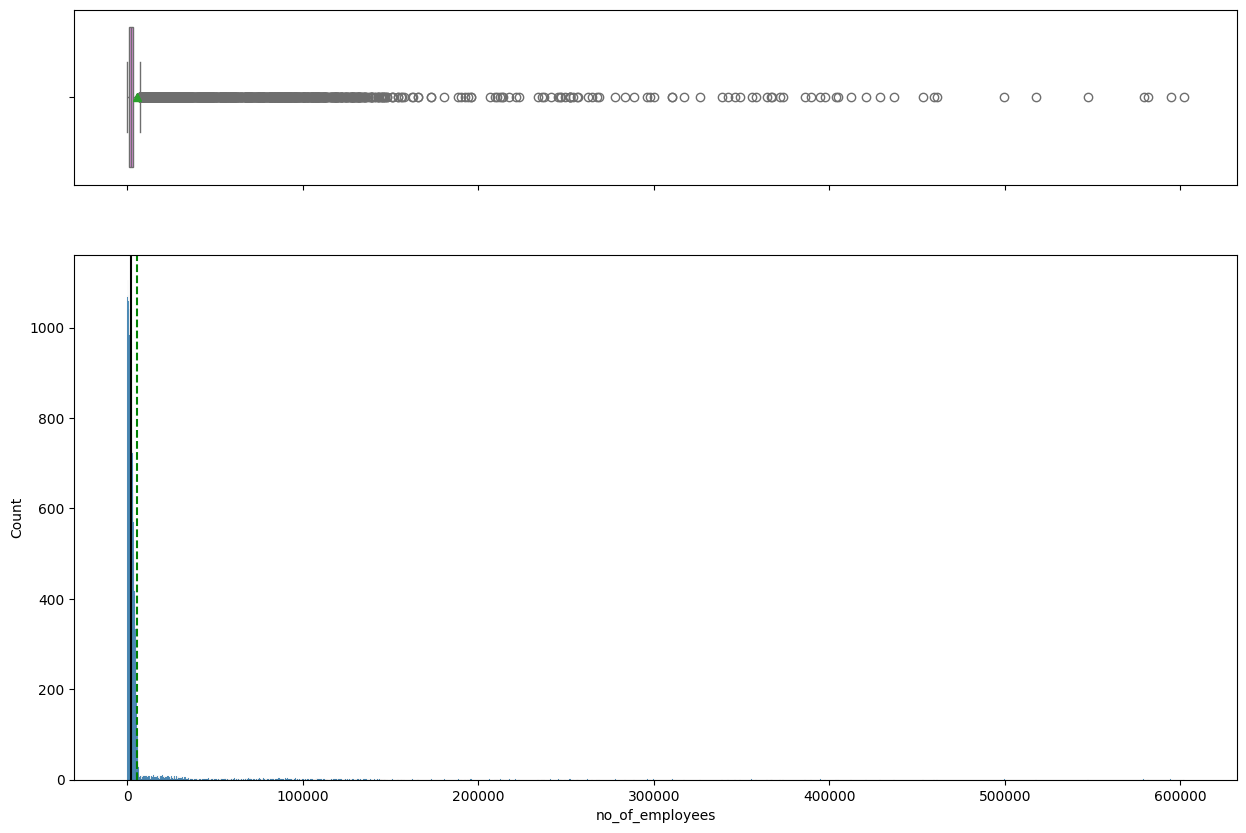

In [18]:
histogram_boxplot(data, "no_of_employees")

- The no_of_employees field has a huge number of outliers.

#### Observation on prevailing_wage

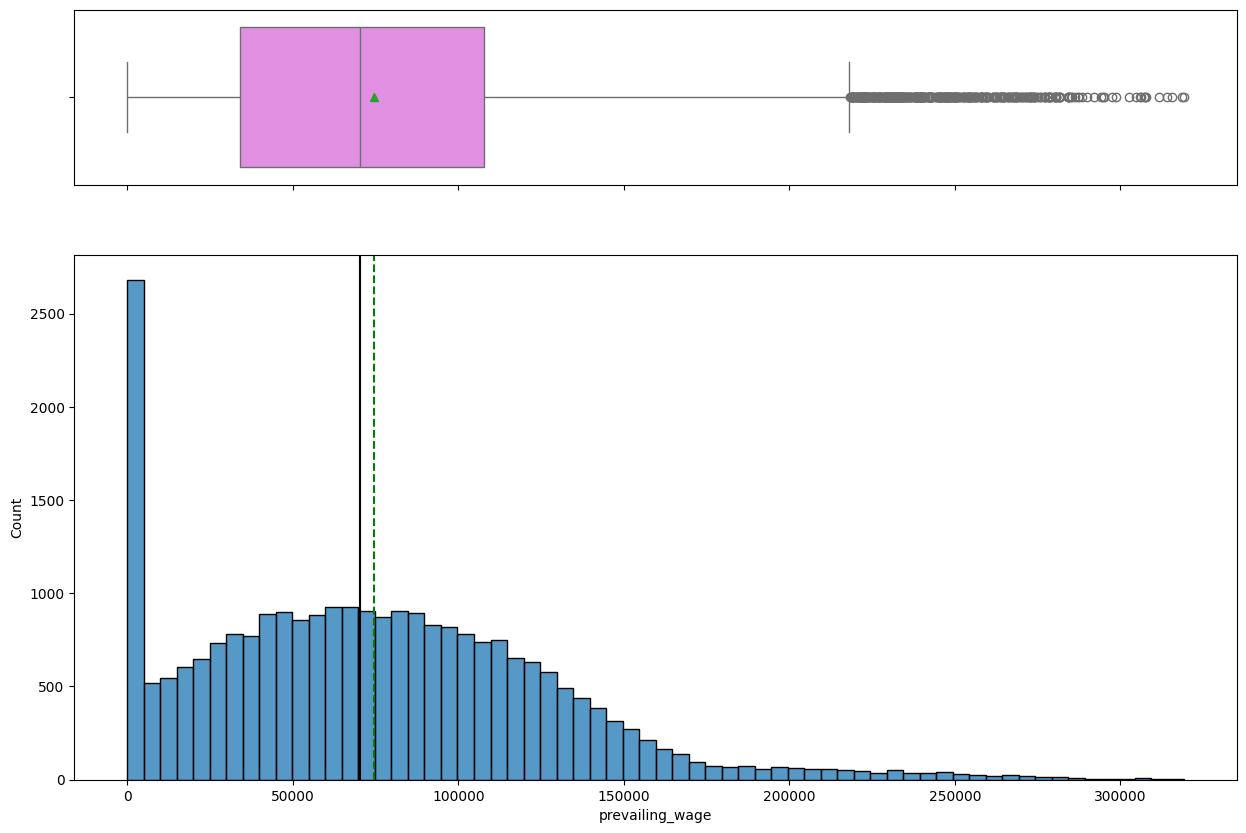

In [19]:
histogram_boxplot(data, "prevailing_wage")

* There is a high range of visa applications whose prevailing wages are slightly greater than 0 as per the histogram. We will now find out the number of applications whose wages are lower than 100

In [20]:
data.loc[data["prevailing_wage"] < 100, "unit_of_wage"].value_counts()

,count
unit_of_wage,
Hour,176


**Leading Questions**:
1. Those with higher education may want to travel abroad for a well-paid job. Does education play a role in Visa certification?

2. How does the visa status vary across different continents?

3. Experienced professionals might look abroad for opportunities to improve their lifestyles and career development. Does work experience influence visa status?

4. In the United States, employees are paid at different intervals. Which pay unit is most likely to be certified for a visa?

5. The US government has established a prevailing wage to protect local talent and foreign workers. How does the visa status change with the prevailing wage?

#### Observations on continent

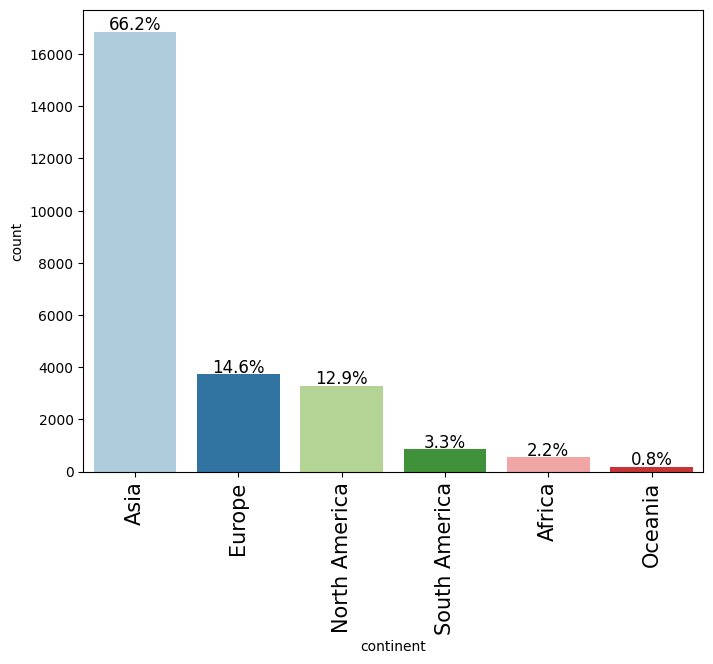

In [21]:
labeled_barplot(data, "continent", perc=True)

* The maximum cases have been filed in Asia (66.6%) and the minimum in Oceania (0.8%)

#### Observations on education_of_employee

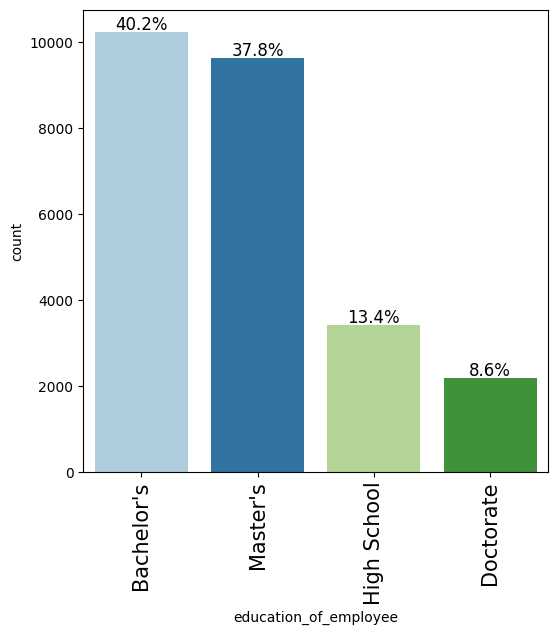

In [22]:
labeled_barplot(data, "education_of_employee", perc=True)

* The maximum visa cases are applied by Bachelor's degree followed by Master's while the least number of Doctorate have applied for visa.

#### Observations on has_job_experience

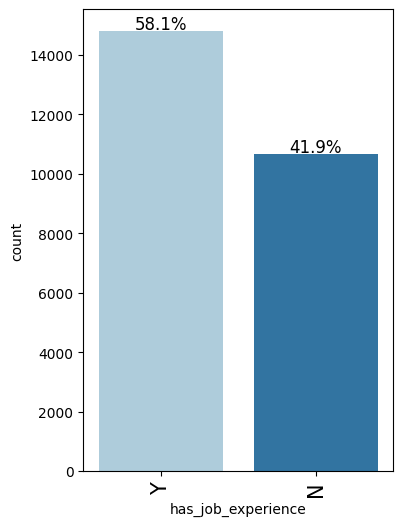

In [23]:
labeled_barplot(data, "has_job_experience", perc=True)

* More number of experienced people applied for visa than the non-experienced people.

#### Observations on requires_job_training

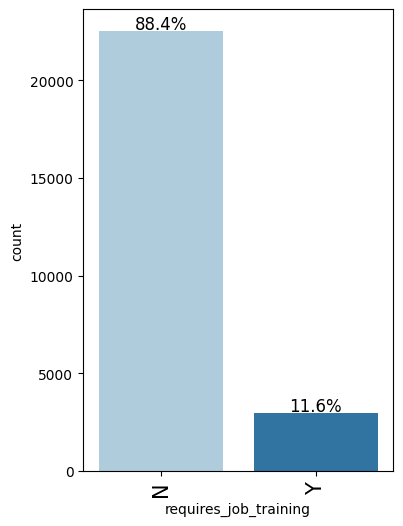

In [24]:
labeled_barplot(data, "requires_job_training", perc=True)

* More number of people who do not require job training applied for visa than the people who require job training.

#### Observations on region_of_employment

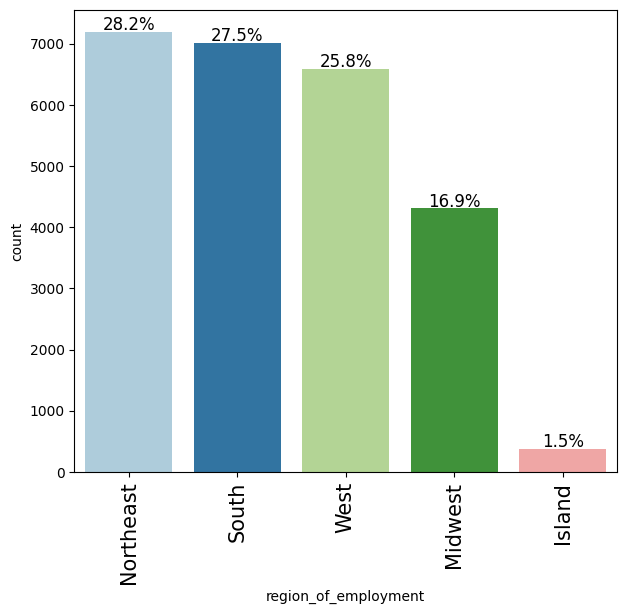

In [25]:
labeled_barplot(data, "region_of_employment", perc=True)

* Maximum number of visa cases are applied for Northeast and south region while Island is the least preferrable region.

#### Observations on unit_of_wage

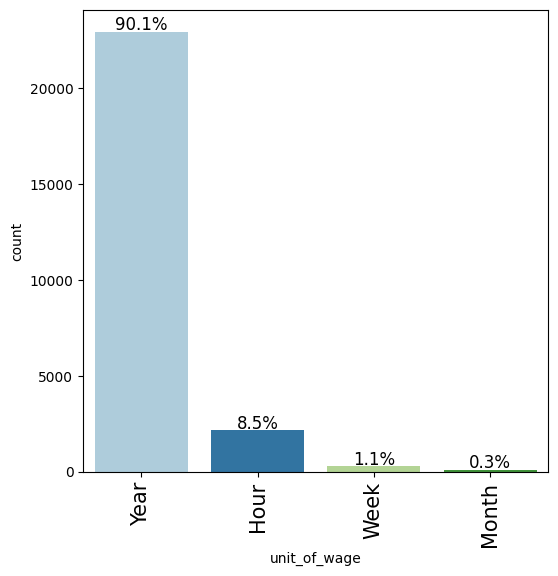

In [26]:
labeled_barplot(data, "unit_of_wage", perc=True)

* Most of the cases who applied for visa prefer yearly wage (90.1%) and while least prefer monthly wage.

#### Observations on full_time_position

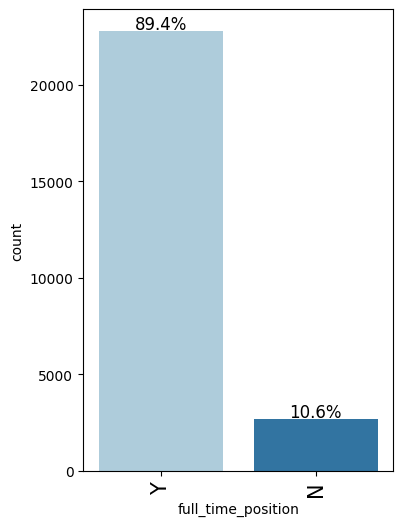

In [27]:
labeled_barplot(data, "full_time_position", perc=True)

* Most of the cases prefer full time position (89.4%) while only 10.6% do not prefer full time position.

#### Observations on case_status

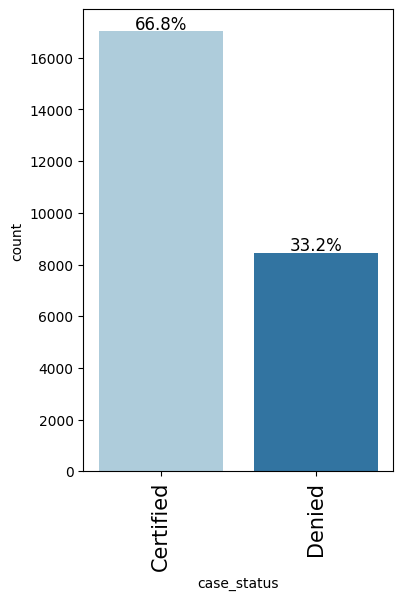

In [28]:
labeled_barplot(data, "case_status", perc=True)

* Based on the dataset, around 66.8% cases certified while 33.2% have been denied.

### Bivariate analysis

**Correlation Check**

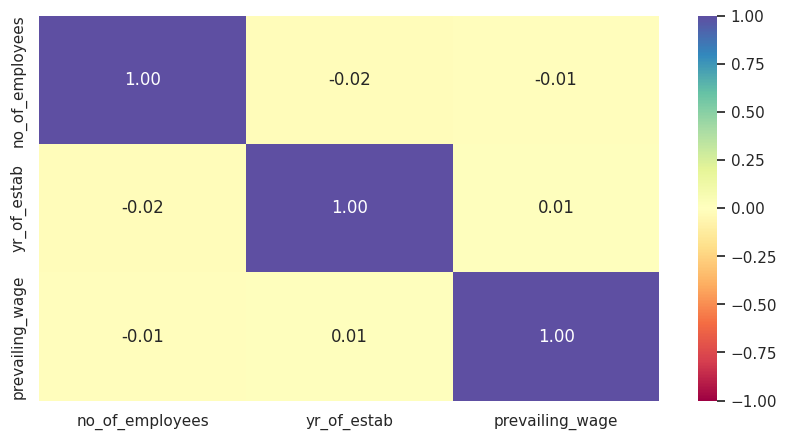

In [29]:
num_cols = data.select_dtypes(include=np.number).columns.tolist()
sns.set(rc={'figure.figsize':(8,4)})
plt.figure(figsize=(10, 5))
sns.heatmap(
    data[num_cols].corr(), annot=True, vmin=-1, vmax=1, fmt=".2f", cmap="Spectral"
)
plt.show()
plt.show()


* Based on the heatmap, all the numeric columns are not that correlated with each other. Hence we cannot decide much based on the heatmap.

**Creating functions that will help us with further analysis.**

In [30]:
### function to plot distributions wrt target


def distribution_plot_wrt_target(data, predictor, target):

    fig, axs = plt.subplots(2, 2, figsize=(12, 10))

    target_uniq = data[target].unique()

    axs[0, 0].set_title("Distribution of target for target=" + str(target_uniq[0]))
    sns.histplot(
        data=data[data[target] == target_uniq[0]],
        x=predictor,
        kde=True,
        ax=axs[0, 0],
        color="teal",
        stat="density",
    )

    axs[0, 1].set_title("Distribution of target for target=" + str(target_uniq[1]))
    sns.histplot(
        data=data[data[target] == target_uniq[1]],
        x=predictor,
        kde=True,
        ax=axs[0, 1],
        color="orange",
        stat="density",
    )

    axs[1, 0].set_title("Boxplot w.r.t target")
    sns.boxplot(data=data, x=target, y=predictor, ax=axs[1, 0], palette="gist_rainbow")

    axs[1, 1].set_title("Boxplot (without outliers) w.r.t target")
    sns.boxplot(
        data=data,
        x=target,
        y=predictor,
        ax=axs[1, 1],
        showfliers=False,
        palette="gist_rainbow",
    )

    plt.tight_layout()
    plt.show()

In [31]:
def stacked_barplot(data, predictor, target):
    """
    Print the category counts and plot a stacked bar chart

    data: dataframe
    predictor: independent variable
    target: target variable
    """
    count = data[predictor].nunique()
    sorter = data[target].value_counts().index[-1]
    tab1 = pd.crosstab(data[predictor], data[target], margins=True).sort_values(
        by=sorter, ascending=False
    )
    print(tab1)
    print("-" * 120)
    tab = pd.crosstab(data[predictor], data[target], normalize="index").sort_values(
        by=sorter, ascending=False
    )
    tab.plot(kind="bar", stacked=True, figsize=(count + 5, 5))
    plt.legend(
        loc="lower left", frameon=False,
    )
    plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
    plt.show()

**Impact of higher education on visa status (Case status)**

case_status            Certified  Denied    All
education_of_employee                          
All                        17018    8462  25480
Bachelor's                  6367    3867  10234
High School                 1164    2256   3420
Master's                    7575    2059   9634
Doctorate                   1912     280   2192
------------------------------------------------------------------------------------------------------------------------


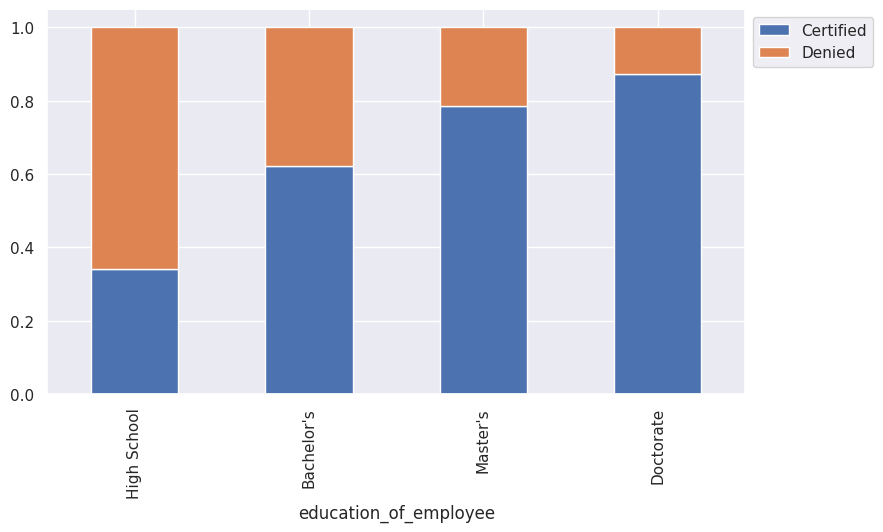

In [32]:
stacked_barplot(data, "education_of_employee", "case_status")

* Based on the chart, level of education plays a greater role in case being certified or denied.  The chances of getting certified is more on Dataset and least in case of High school based on the visualization.

**Visa status in different continents**

case_status    Certified  Denied    All
continent                              
All                17018    8462  25480
Asia               11012    5849  16861
North America       2037    1255   3292
Europe              2957     775   3732
South America        493     359    852
Africa               397     154    551
Oceania              122      70    192
------------------------------------------------------------------------------------------------------------------------


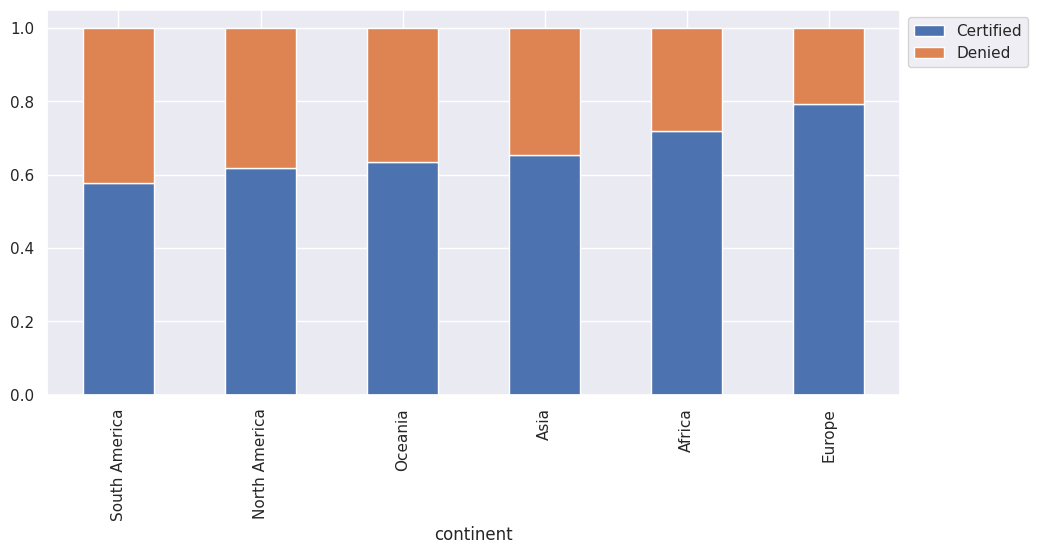

In [33]:
stacked_barplot(data, "continent", "case_status")

* Based on the chart, chances of getting are more in case of Europe and least in case of South America.

**Impact of work experience on Visa Status**

case_status         Certified  Denied    All
has_job_experience                          
All                     17018    8462  25480
N                        5994    4684  10678
Y                       11024    3778  14802
------------------------------------------------------------------------------------------------------------------------


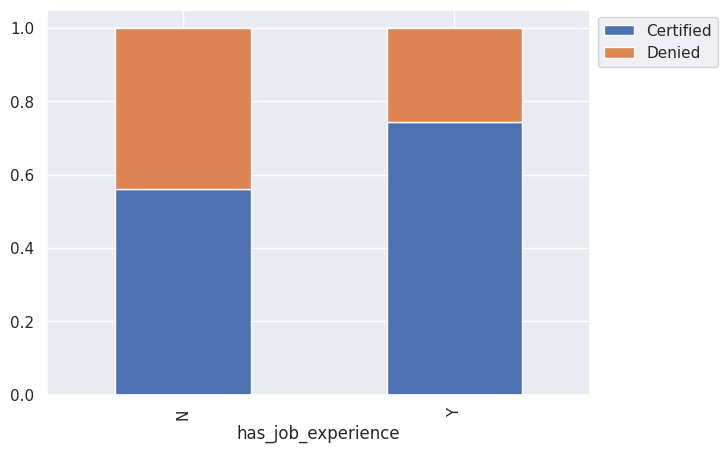

In [34]:
stacked_barplot(data, "has_job_experience", "case_status")

* Based on the chart, cases for which there is job experience is more certified than that of cases with no prior job expience. Hence chances of getting certified could be more for experienced people.

**Impact of unit of wage on Visa Status**

case_status   Certified  Denied    All
unit_of_wage                          
All               17018    8462  25480
Year              16047    6915  22962
Hour                747    1410   2157
Week                169     103    272
Month                55      34     89
------------------------------------------------------------------------------------------------------------------------


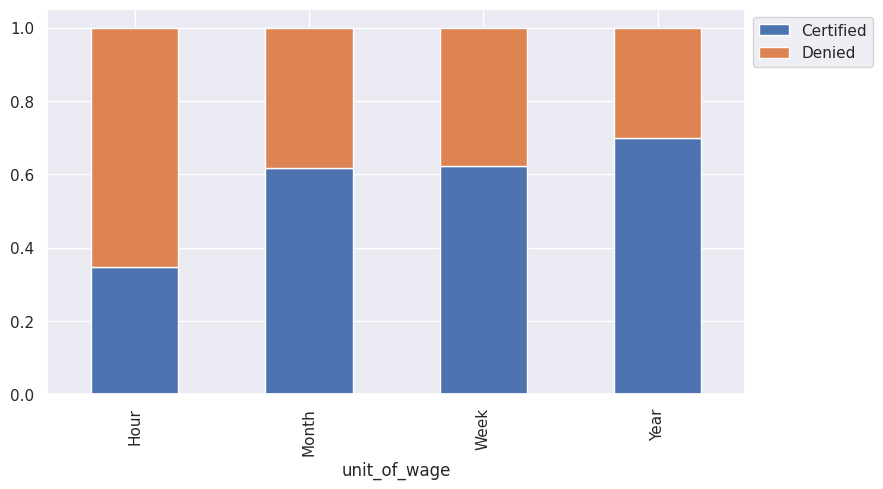

In [35]:
stacked_barplot(data, "unit_of_wage", "case_status")

* Based on the chart, cases for which unit of wage is yearly is slightly more certified than the rest of the wage types.

**Impact of different regions on Visa Status**

case_status           Certified  Denied    All
region_of_employment                          
All                       17018    8462  25480
Northeast                  4526    2669   7195
West                       4100    2486   6586
South                      4913    2104   7017
Midwest                    3253    1054   4307
Island                      226     149    375
------------------------------------------------------------------------------------------------------------------------


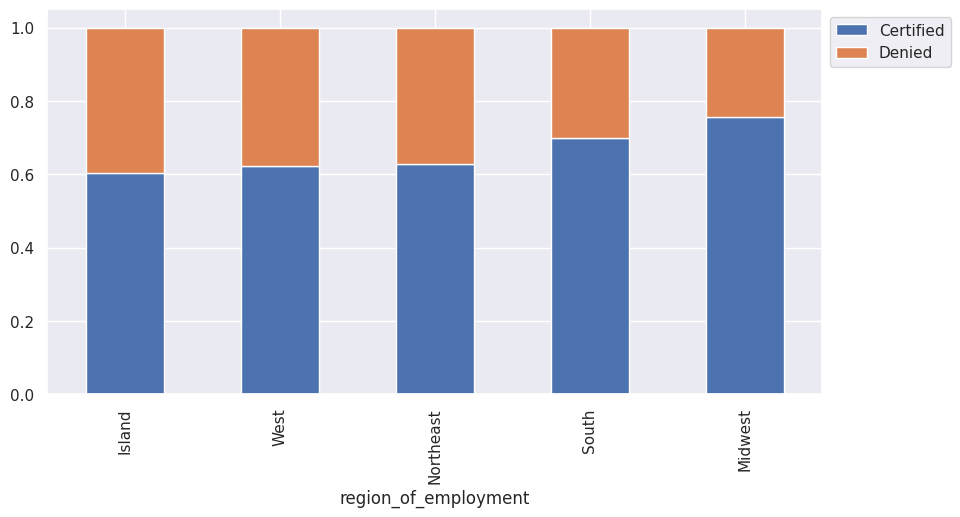

In [36]:
stacked_barplot(data, "region_of_employment", "case_status")

* Based on the chart, cases whose epmoloyment are in Midwest region are more certified compared to other regions. Chances of getting certified could be slightly more in this region and least in Island region.

**Impact of position type on Visa Status**

case_status         Certified  Denied    All
full_time_position                          
All                     17018    8462  25480
Y                       15163    7610  22773
N                        1855     852   2707
------------------------------------------------------------------------------------------------------------------------


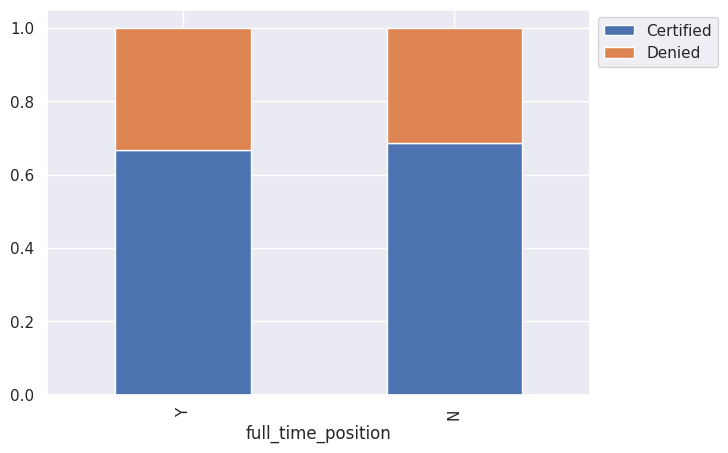

In [37]:
stacked_barplot(data, "full_time_position", "case_status")

* Based on the chart, cases irrespective of having full time position or not have more cases certified than rejected.

**Impact of job training requirement on visa status**

case_status            Certified  Denied    All
requires_job_training                          
All                        17018    8462  25480
N                          15012    7513  22525
Y                           2006     949   2955
------------------------------------------------------------------------------------------------------------------------


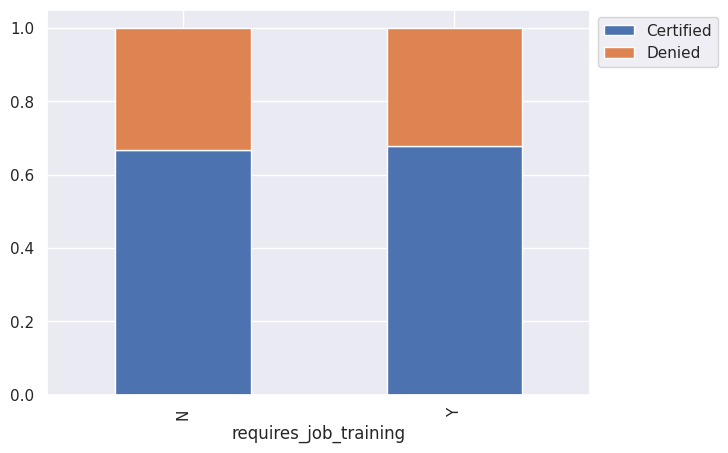

In [38]:
stacked_barplot(data, "requires_job_training", "case_status")

* Based on the chart, cases irrespective the cases requiring job training or not have more cases certified than rejected.

**Change in Visa status based on prevailing age**

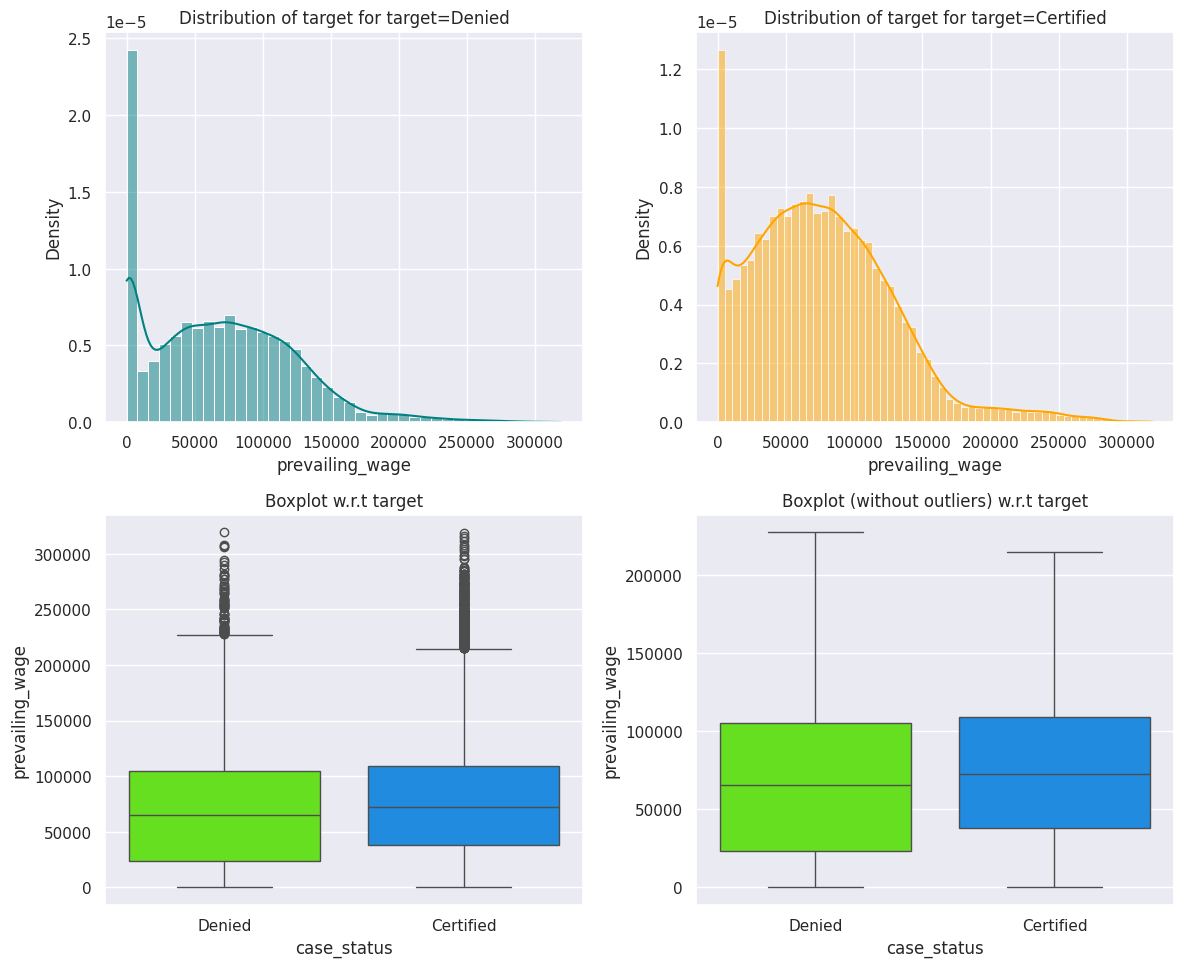

In [39]:
distribution_plot_wrt_target(data, "prevailing_wage", "case_status")

* Based on the chart, cases who wages are more are certified slightly more than denied. Hence there could be more chances of certified than denied if the wages are more.

**Change in Prevailing Wage across different regions**

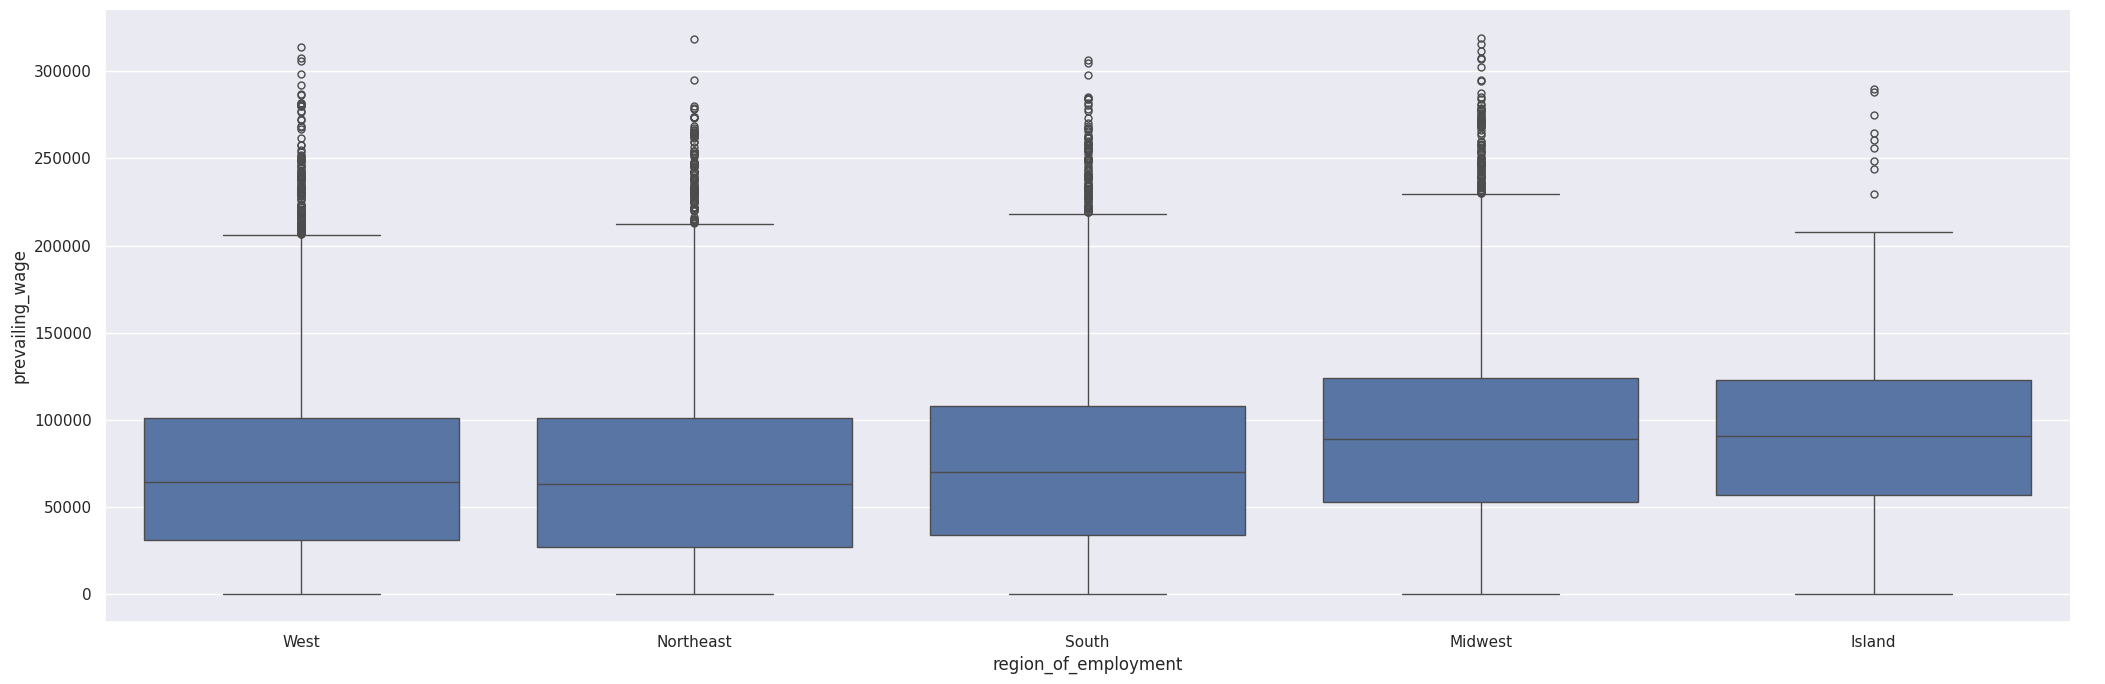

In [40]:
sns.set(rc={"figure.figsize": (10, 6)})
sns.catplot(
    x="region_of_employment",
    y="prevailing_wage",
    kind="box",
    data=data,
    height=7,
    aspect=3,
)

* Based on the visual, Midwest region has slightly more wage than other regions.

**Demand on education across different regions**

<Axes: xlabel='region_of_employment', ylabel='count'>

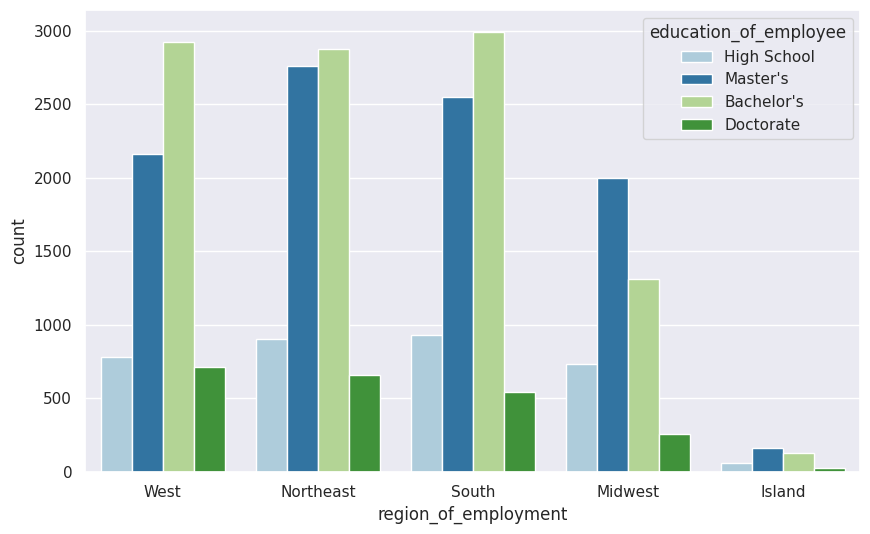

In [41]:
sns.set(rc={"figure.figsize": (10, 6)})
sns.countplot(
    data=data, x="region_of_employment", hue="education_of_employee", palette="Paired"
)

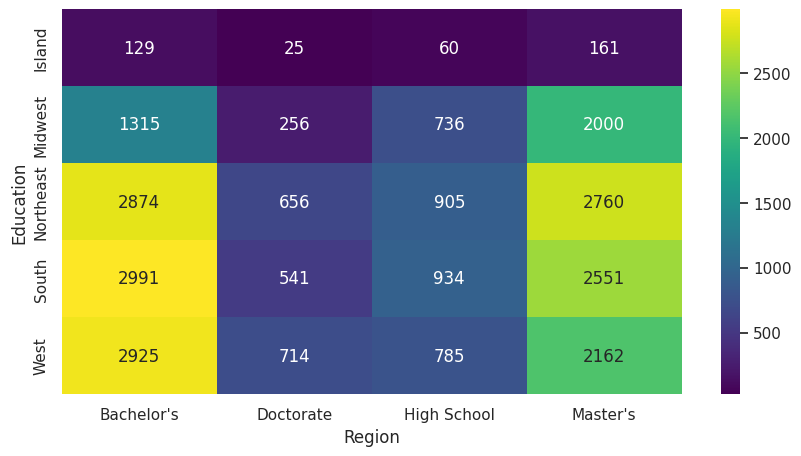

In [42]:
plt.figure(figsize=(10, 5))
sns.heatmap(
    pd.crosstab(
        index=data["region_of_employment"], columns=data["education_of_employee"]
    ),
    annot=True,
    fmt="g",
    cmap="viridis",
)

plt.ylabel("Education")
plt.xlabel("Region")
plt.show()

* Based on the visual, cases who have done bacherlor's and master's are high in all refions while high school and doctorate is less.

## Data Preprocessing

- Missing value treatment (if needed)
- Feature engineering
- Outlier detection and treatment (if needed)
- Preparing data for modeling
- Any other preprocessing steps (if needed)

### Outlier Check

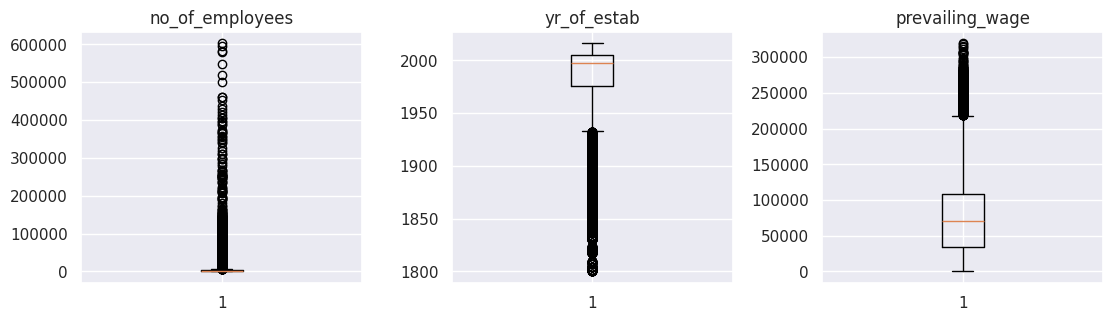

In [43]:
# outlier detection using boxplot
numeric_columns = data.select_dtypes(include=np.number).columns.tolist()


plt.figure(figsize=(15, 12))

for i, variable in enumerate(numeric_columns):
    plt.subplot(4, 4, i + 1)
    plt.boxplot(data[variable], whis=1.5)
    plt.tight_layout()
    plt.title(variable)

plt.show()

- There are quite a few outliers in the data.
- However, we will not treat them as they are proper values.

### Data Preparation for modeling

- We want to predict which visa will be certified.
- Before we proceed to build a model, we'll have to encode categorical features.
- We'll split the data into train and test to be able to evaluate the model that we build on the train data.

**Converting the case_status value to 1 and 0**

In [44]:
data["case_status"] = data["case_status"].apply(lambda x: 1 if x == "Certified" else 0)

**Splitting the data as training data and test data**

In [45]:
X = data.drop(["case_status"], axis=1)
y = data["case_status"]

X = pd.get_dummies(X, drop_first=True)

* When classification problems exhibit a significant imbalance in the distribution of the target classes, it is good to use stratified sampling to ensure that relative class frequencies are approximately preserved in train and test sets.
* This is done using the `stratify` parameter in the train_test_split function.

In [46]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=1, stratify=y
)
print(X_train.shape, X_test.shape)

(17836, 21) (7644, 21)


In [47]:
print("Shape of Training set : ", X_train.shape)
print("Shape of test set : ", X_test.shape)
print("Percentage of classes in training set:")
print(y_train.value_counts(normalize=True))
print("Percentage of classes in test set:")
print(y_test.value_counts(normalize=True))

Shape of Training set :  (17836, 21)
Shape of test set :  (7644, 21)
Percentage of classes in training set:
case_status
1    0.667919
0    0.332081
Name: proportion, dtype: float64
Percentage of classes in test set:
case_status
1    0.667844
0    0.332156
Name: proportion, dtype: float64


## Model evaluation criterion

### Model can make wrong predictions as:

1. Predicting that the visa application will get certified but the visa application should get denied.
2. Predicting that the visa application will be denied but the visa application should get certified.

### Which case is more important?
* Both the cases are important as:

* If the visa gets certified for the wrong person for whom it has to be denied, a valuable person for whom the job position should be provided will lose the opportunity to work in that position

* If the visa gets denied for a person for whom it had to be certified, the U.S will lose a good resource who can contribute to that position and to the country


### How to reduce the losses?

* As both the above cases are important where both False positives as well as False negatives should be reduced, `F1 Score` can be used a metric for model evaluation
* We will use balanced class weights so that model focuses equally on both classes.

**First, let's create functions to calculate different metrics and confusion matrix so that we don't have to use the same code repeatedly for each model.**
* The model_performance_classification_sklearn function will be used to check the model performance of models.
* The confusion_matrix_sklearn function will be used to plot the confusion matrix.

In [48]:
# defining a function to compute different metrics to check performance of a classification model built using sklearn


def model_performance_classification_sklearn(model, predictors, target):
    """
    Function to compute different metrics to check classification model performance

    model: classifier
    predictors: independent variables
    target: dependent variable
    """

    # predicting using the independent variables
    pred = model.predict(predictors)

    acc = accuracy_score(target, pred)  # to compute Accuracy
    recall = recall_score(target, pred)  # to compute Recall
    precision = precision_score(target, pred)  # to compute Precision
    f1 = f1_score(target, pred)  # to compute F1-score

    # creating a dataframe of metrics
    df_perf = pd.DataFrame(
        {"Accuracy": acc, "Recall": recall, "Precision": precision, "F1": f1,},
        index=[0],
    )

    return df_perf

In [49]:
def confusion_matrix_sklearn(model, predictors, target):
    """
    To plot the confusion_matrix with percentages

    model: classifier
    predictors: independent variables
    target: dependent variable
    """
    y_pred = model.predict(predictors)
    cm = confusion_matrix(target, y_pred)
    labels = np.asarray(
        [
            ["{0:0.0f}".format(item) + "\n{0:.2%}".format(item / cm.flatten().sum())]
            for item in cm.flatten()
        ]
    ).reshape(2, 2)

    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=labels, fmt="")
    plt.ylabel("True label")
    plt.xlabel("Predicted label")

## Model Building

### Decision Tree Model

#### Building a decision tree Model

In [50]:
dtree = DecisionTreeClassifier(random_state=1, class_weight="balanced")
dtree.fit(X_train, y_train)

DecisionTreeClassifier(class_weight='balanced', random_state=1)

#### Checking model performance on training set

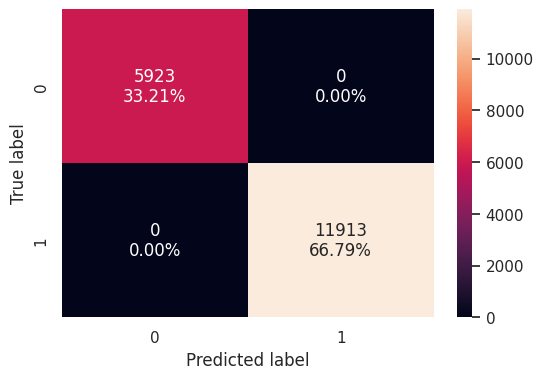

In [51]:
confusion_matrix_sklearn(dtree, X_train, y_train)

**Confusion Matrix -**
* Visa case is certified and the model predicted it correctly that  it will be certified : True Positive (observed=1,predicted=1)

* Visa case is denied but the and the model predicted it will be certified : False Positive (observed=0,predicted=1)

*  Visa case is denied and the model predicted it correctly that  it will be denied : True Negative (observed=0,predicted=0)

* Visa case is certified but the and the model predicted it will be denied : False Negative (observed=1,predicted=0)
                                                        

In [52]:
decision_tree_perf_train = model_performance_classification_sklearn(
    dtree, X_train, y_train
)
decision_tree_perf_train

,Accuracy,Recall,Precision,F1
0,1.0,1.0,1.0,1.0


#### Checking model performance on test set

In [53]:
decision_tree_perf_test_without = model_performance_classification_sklearn(
    dtree, X_test, y_test
)
decision_tree_perf_test_without

,Accuracy,Recall,Precision,F1
0,0.654893,0.747502,0.738819,0.743135


* Decision tree is working well on the training data but is not able to generalize well on the test data
* The decision tree is overfitting the training data
* Let's try hyperparameter tuning and see if the model performance improves.

### Hyperparameter Tuning - Decision Tree

In [54]:
# Choose the type of classifier.
dtree_estimator = DecisionTreeClassifier(class_weight="balanced", random_state=1)

# Grid of parameters to choose from
parameters = {
    "max_depth": np.arange(5, 16, 5),
    "min_samples_leaf": [3, 5, 7],
    "max_leaf_nodes": [2, 5],
    "min_impurity_decrease": [0.0001, 0.001],
}

# Type of scoring used to compare parameter combinations
scorer = metrics.make_scorer(metrics.f1_score)

# Run the grid search
grid_obj = GridSearchCV(dtree_estimator, parameters, scoring=scorer, cv=5)

grid_obj = grid_obj.fit(X_train, y_train)

# Set the clf to the best combination of parameters
dtree_estimator = grid_obj.best_estimator_

# Fit the best algorithm to the data.
dtree_estimator.fit(X_train, y_train)

DecisionTreeClassifier(class_weight='balanced', max_depth=np.int64(5),
                       max_leaf_nodes=2, min_impurity_decrease=0.0001,
                       min_samples_leaf=3, random_state=1)

#### Confusion Matrix for for train data on tuned estimator

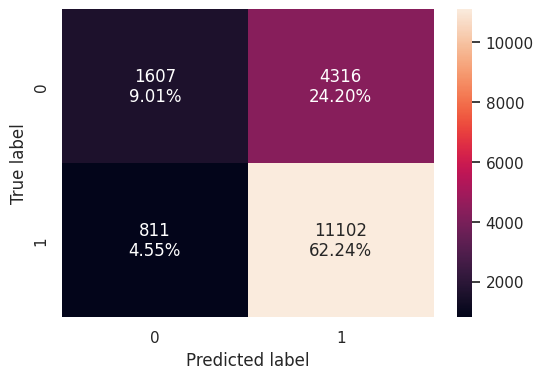

In [55]:
confusion_matrix_sklearn(dtree_estimator, X_train, y_train)

#### Check performance for train data on tuned estimator

In [56]:
dtree_estimator_model_train_perf = model_performance_classification_sklearn(
    dtree_estimator, X_train, y_train
)
dtree_estimator_model_train_perf

,Accuracy,Recall,Precision,F1
0,0.712548,0.931923,0.720067,0.812411


#### Confusion Matrix for for test data on tuned estimator

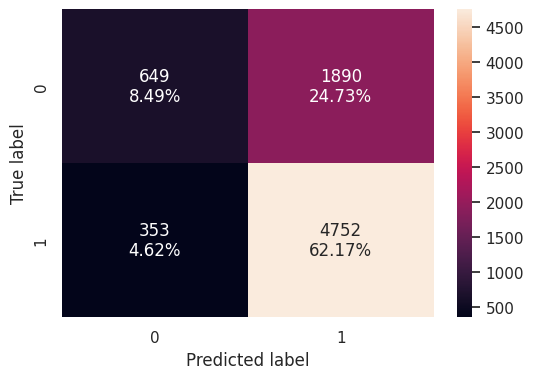

In [57]:
confusion_matrix_sklearn(dtree_estimator, X_test, y_test)

#### Check performance for test data on tuned estimator

In [58]:
dtree_estimator_model_test_perf = model_performance_classification_sklearn(
    dtree_estimator, X_test, y_test
)
dtree_estimator_model_test_perf

,Accuracy,Recall,Precision,F1
0,0.706567,0.930852,0.715447,0.809058


* The overfitting has reduced but the rest of the scores almost remain the same.
* Let's try some other models.

## Building bagging and boosting models

### Bagging - Model Building and Hyperparameter Tuning

In [59]:
bagging = BaggingClassifier(random_state=1)
bagging.fit(X_train, y_train)

BaggingClassifier(random_state=1)

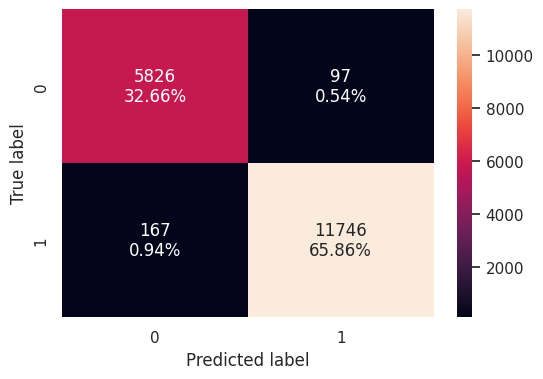

In [60]:
confusion_matrix_sklearn(bagging, X_train, y_train)

In [61]:
bagging_model_train_perf = model_performance_classification_sklearn(
    bagging, X_train, y_train
)
bagging_model_train_perf

,Accuracy,Recall,Precision,F1
0,0.985198,0.985982,0.99181,0.988887


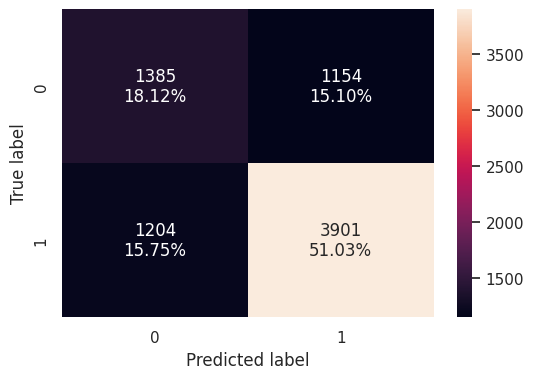

In [62]:
confusion_matrix_sklearn(bagging, X_test, y_test)

In [63]:
bagging_model_test_perf = model_performance_classification_sklearn(
    bagging, X_test, y_test
)
bagging_model_test_perf

,Accuracy,Recall,Precision,F1
0,0.691523,0.764153,0.771711,0.767913


* This model overfits the training data.
* The F1-score has reduced compared to tuned decision tree. Let's tune this to get more clarity.

### Hyperparameter Tuning - Bagging Classifier

In [64]:
# Choose the type of bagging classifier.
bagging_estimator_tuned = BaggingClassifier(random_state=1, bootstrap=True)

# Grid of parameters to choose from
parameters = {
    "max_samples": [0.7, 0.9],
    "max_features": [0.7, 0.9],
    "n_estimators": np.arange(90, 111, 10),
}

# Type of scoring used to compare parameter combinations
acc_scorer = metrics.make_scorer(metrics.f1_score)

# Run the grid search
grid_obj = GridSearchCV(bagging_estimator_tuned, parameters, scoring=acc_scorer, cv=5)
grid_obj = grid_obj.fit(X_train, y_train)

# Set the clf to the best combination of parameters
bagging_estimator_tuned = grid_obj.best_estimator_

# Fit the best algorithm to the data.
bagging_estimator_tuned.fit(X_train, y_train)

BaggingClassifier(max_features=0.7, max_samples=0.7, n_estimators=np.int64(100),
                  random_state=1)

#### Checking model performance on training set

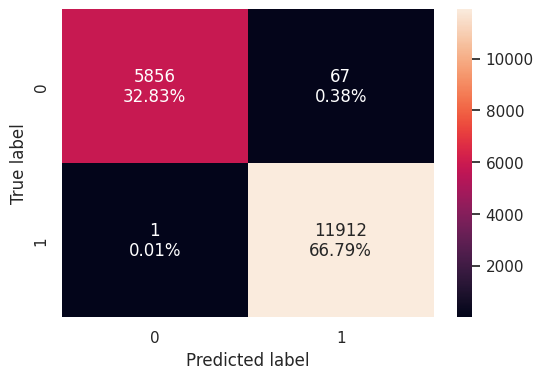

In [65]:
confusion_matrix_sklearn(bagging_estimator_tuned, X_train, y_train)

In [66]:
bagging_estimator_tuned_model_train_perf = model_performance_classification_sklearn(
    bagging_estimator_tuned, X_train, y_train
)
bagging_estimator_tuned_model_train_perf

,Accuracy,Recall,Precision,F1
0,0.996187,0.999916,0.994407,0.997154


#### Checking model performance on test set

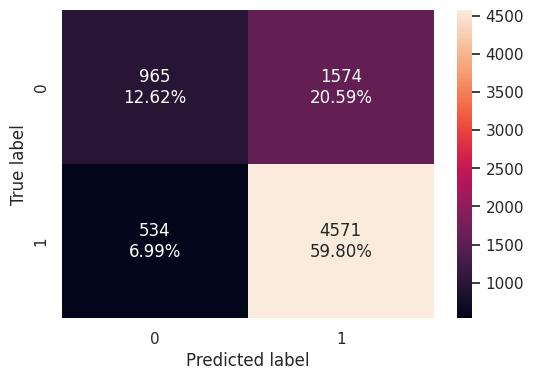

In [67]:
confusion_matrix_sklearn(bagging_estimator_tuned, X_test, y_test)

In [68]:
bagging_estimator_tuned_model_test_perf = model_performance_classification_sklearn(
    bagging_estimator_tuned, X_test, y_test
)
bagging_estimator_tuned_model_test_perf

,Accuracy,Recall,Precision,F1
0,0.724228,0.895397,0.743857,0.812622


* The f1-score for the tuned model has increased for test data compared to the original model.
* Let's analyze the other models

### Random Forest

In [69]:
rf_estimator = RandomForestClassifier(random_state=1)
rf_estimator.fit(X_train, y_train)

RandomForestClassifier(random_state=1)

#### Checking model performance on training set

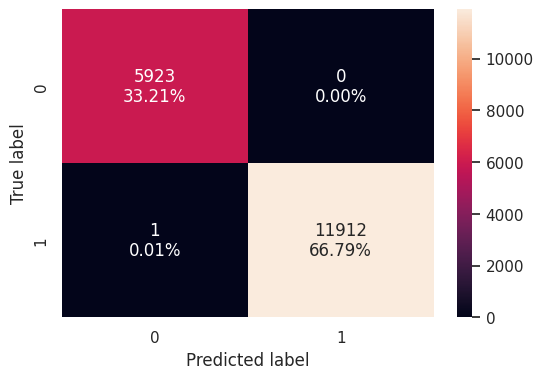

In [70]:
confusion_matrix_sklearn(rf_estimator, X_train, y_train)

In [71]:
# Calculating different metrics
rf_estimator_model_train_perf = model_performance_classification_sklearn(
    rf_estimator, X_train, y_train
)
rf_estimator_model_train_perf

,Accuracy,Recall,Precision,F1
0,0.999944,0.999916,1.0,0.999958


#### Checking model performance on test set

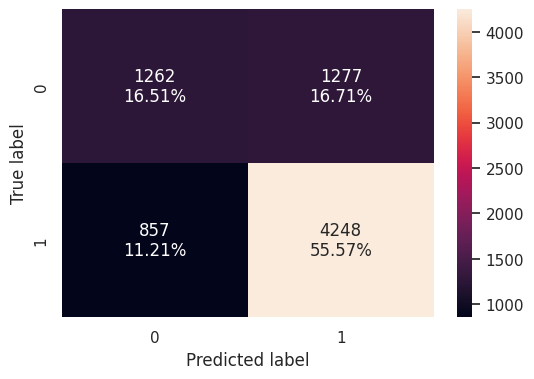

In [72]:
confusion_matrix_sklearn(rf_estimator, X_test, y_test)

In [73]:
# Calculating different metrics
rf_estimator_model_test_perf = model_performance_classification_sklearn(
    rf_estimator, X_test, y_test
)
rf_estimator_model_test_perf

,Accuracy,Recall,Precision,F1
0,0.720827,0.832125,0.768869,0.799247


* This model overfits the training data set. But the f1-score is reduced for the test data compared to the previous tuned model.
* Let's analyze how the tuning works for this model.

### Hyperparameter Tuning - Random Forest


In [74]:
# Choose the type of classifier.
rf_tuned = RandomForestClassifier(random_state=1, oob_score=True, bootstrap=True)

parameters = {
    "max_depth": list(np.arange(5, 15, 5)),
    "max_features": ["sqrt", "log2"],
    "min_samples_split": [5, 7],
    "n_estimators": np.arange(15, 26, 5),
}

# Type of scoring used to compare parameter combinations
acc_scorer = metrics.make_scorer(metrics.f1_score)

# Run the grid search
grid_obj = GridSearchCV(rf_tuned, parameters, scoring=acc_scorer, cv=5, n_jobs=-1)
grid_obj = grid_obj.fit(X_train, y_train)
rf_tuned = grid_obj.best_estimator_

# Fit the best algorithm to the data.
rf_tuned.fit(X_train, y_train)

RandomForestClassifier(max_depth=np.int64(10), min_samples_split=7,
                       n_estimators=np.int64(20), oob_score=True,
                       random_state=1)

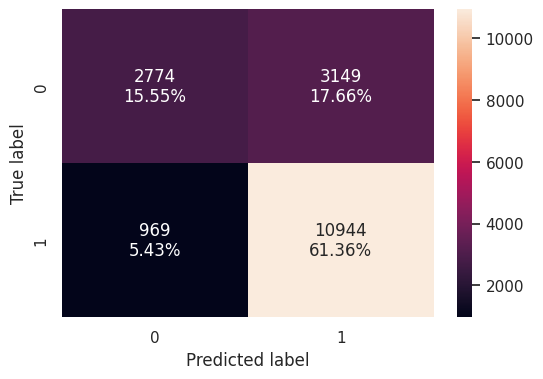

In [75]:
confusion_matrix_sklearn(rf_tuned, X_train, y_train)

In [76]:
rf_tuned_model_train_perf = model_performance_classification_sklearn(
    rf_tuned, X_train, y_train
)
print("Training performance \n", rf_tuned_model_train_perf)

Training performance 
    Accuracy   Recall  Precision        F1
0  0.769119  0.91866   0.776556  0.841652


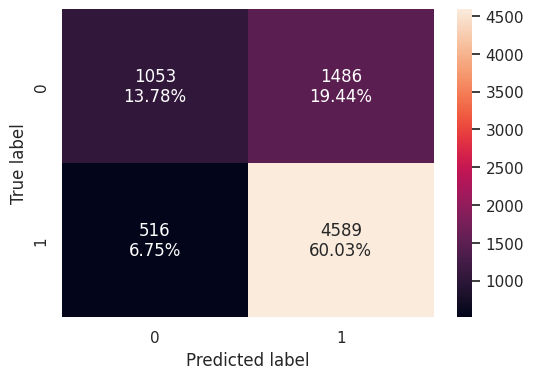

In [77]:
confusion_matrix_sklearn(rf_tuned, X_test, y_test)

In [78]:
rf_tuned_model_test_perf = model_performance_classification_sklearn(
    rf_tuned, X_test, y_test
)
print("Training performance \n", rf_tuned_model_test_perf)

Training performance 
    Accuracy    Recall  Precision       F1
0  0.738095  0.898923   0.755391  0.82093


* The tuned model does not overfit the training data set.
* The f1-score increased slightly for test data set compared to original model.
* Let's analyze the other boosting models

## Boosting

### AdaBoost Classifier

In [79]:
# Fitting the model
ab_classifier = AdaBoostClassifier(random_state=1)
ab_classifier.fit(X_train, y_train)

AdaBoostClassifier(random_state=1)

#### Checking model performance on train set

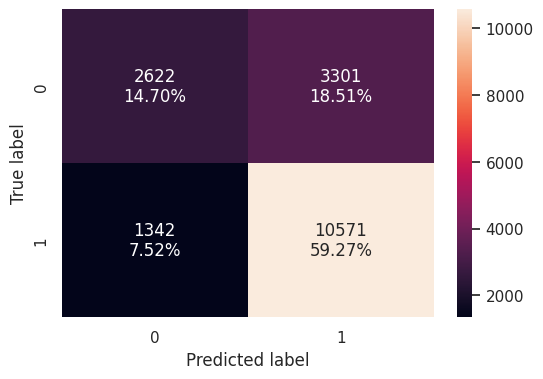

In [80]:
confusion_matrix_sklearn(ab_classifier, X_train, y_train)

In [81]:
ab_classifier_model_train_perf = model_performance_classification_sklearn(
    ab_classifier, X_train, y_train
)
print(ab_classifier_model_train_perf)

   Accuracy   Recall  Precision        F1
0  0.739684  0.88735   0.762039  0.819934


#### Checking model performance on test set

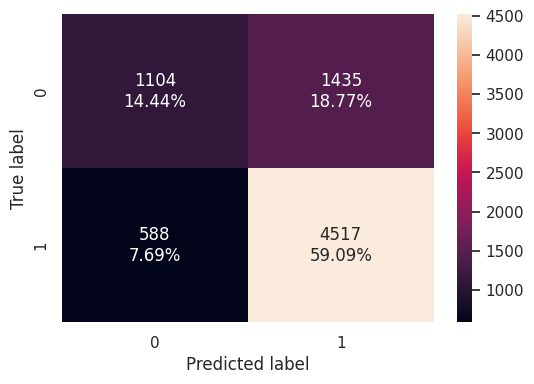

In [82]:
confusion_matrix_sklearn(ab_classifier, X_test, y_test)

In [83]:
ab_classifier_model_test_perf = model_performance_classification_sklearn(
    ab_classifier, X_test, y_test
)
print(ab_classifier_model_test_perf)

   Accuracy    Recall  Precision        F1
0  0.735348  0.884819   0.758905  0.817039


* This model does not overfit the training data set.
* It is almost same for both training and test data set.
* It is almost having same value as tuned rf model.
* Let us tune this model to see if there is any improvement.

### Hyperparameter Tuning - AdaBoost Classifier

In [84]:
# Choose the type of classifier.
abc_tuned = AdaBoostClassifier(random_state=1)

# Grid of parameters to choose from
parameters = {
    # Let's try different max_depth for base_estimator
    "base_estimator": [
        DecisionTreeClassifier(max_depth=1, class_weight="balanced", random_state=1),
        DecisionTreeClassifier(max_depth=2, class_weight="balanced", random_state=1),
    ],
    "n_estimators": np.arange(80, 101, 10),
    "learning_rate": np.arange(0.1, 0.4, 0.1),
}

# Type of scoring used to compare parameter  combinations
acc_scorer = metrics.make_scorer(metrics.f1_score)

# Run the grid search
grid_obj = GridSearchCV(abc_tuned, parameters, scoring=scorer, cv=5)
grid_obj = grid_obj.fit(X_train, y_train)

# Set the clf to the best combination of parameters
abc_tuned = grid_obj.best_estimator_

# Fit the best algorithm to the data.
abc_tuned.fit(X_train, y_train)

ValueError: Invalid parameter 'base_estimator' for estimator AdaBoostClassifier(random_state=1). Valid parameters are: ['algorithm', 'estimator', 'learning_rate', 'n_estimators', 'random_state'].

In [ ]:
# Creating confusion matrix
confusion_matrix_sklearn(abc_tuned, X_train, y_train)

In [ ]:
# Calculating different metrics
abc_tuned_model_train_perf = model_performance_classification_sklearn(
    abc_tuned, X_train, y_train
)
print(abc_tuned_model_train_perf)

In [ ]:
# Creating confusion matrix
confusion_matrix_sklearn(abc_tuned, X_test, y_test)

In [ ]:
# Calculating different metrics
abc_tuned_model_test_perf = model_performance_classification_sklearn(
    abc_tuned, X_test, y_test
)
print(abc_tuned_model_test_perf)

* The f1-score for the tuned model has decreased slightly for test data compared to the original model after hypertuning.
* Let's analyze the other models

### Gradient Boosting Classifier

In [ ]:
# Fitting the model
c = GradientBoostingClassifier(random_state=1)
gb_classifier.fit(X_train, y_train)

In [ ]:
confusion_matrix_sklearn(gb_classifier, X_train, y_train)

In [ ]:
gb_classifier_model_train_perf = model_performance_classification_sklearn(
    gb_classifier, X_train, y_train
)
print("Training performance:\n", gb_classifier_model_train_perf)

In [ ]:
confusion_matrix_sklearn(gb_classifier, X_test, y_test)

In [ ]:
gb_classifier_model_test_perf = model_performance_classification_sklearn(
    gb_classifier, X_test, y_test
)
print("Test performance:\n", gb_classifier_model_test_perf)

* This model does not overfit training data set
* This model provides slightly better f1-score compared to other previous models.
* Let us tune this model to see if there is any further improvement.

### Hypertuning - Gradient Classifier

In [ ]:
# Choose the type of classifier.
gbc_tuned = GradientBoostingClassifier(
    init=AdaBoostClassifier(random_state=1), random_state=1
)

# Grid of parameters to choose from
parameters = {
    "n_estimators": [200, 250],
    "subsample": [0.9, 1],
    "max_features": [0.8, 0.9],
    "learning_rate": np.arange(0.1, 0.21, 0.1),
}

# Type of scoring used to compare parameter combinations
acc_scorer = metrics.make_scorer(metrics.f1_score)

# Run the grid search
grid_obj = GridSearchCV(gbc_tuned, parameters, scoring=scorer, cv=5)
grid_obj = grid_obj.fit(X_train, y_train)

# Set the clf to the best combination of parameters
gbc_tuned = grid_obj.best_estimator_

# Fit the best algorithm to the data.
gbc_tuned.fit(X_train, y_train)

In [ ]:
confusion_matrix_sklearn(gb_classifier, X_train, y_train)

In [ ]:
# Calculating different metrics
gbc_tuned_model_train_perf = model_performance_classification_sklearn(
    gbc_tuned, X_train, y_train
)
print("Training performance:\n", gbc_tuned_model_train_perf)

In [ ]:
confusion_matrix_sklearn(gb_classifier, X_test, y_test)

In [ ]:
# Calculating different metrics
gbc_tuned_model_test_perf = model_performance_classification_sklearn(
    gbc_tuned, X_test, y_test
)
print("Training performance:\n", gbc_tuned_model_test_perf)

* The tuned model provides almost similar results (slightly lesser) compared to original model
* There is no improvement in f1-score after hypertuning
* Let us verify how it performs on the other models.

### XGBoost Classifier

In [ ]:
# Fitting the model
xgb_classifier = XGBClassifier(random_state=1, eval_metric="logloss")
xgb_classifier.fit(X_train, y_train)

In [ ]:
confusion_matrix_sklearn(xgb_classifier, X_train, y_train)

In [ ]:
# Calculating different metrics
xgb_classifier_model_train_perf = model_performance_classification_sklearn(
    xgb_classifier, X_train, y_train
)
print("Training performance:\n", xgb_classifier_model_train_perf)

In [ ]:
confusion_matrix_sklearn(xgb_classifier, X_test, y_test)

In [ ]:
xgb_classifier_model_test_perf = model_performance_classification_sklearn(
    xgb_classifier, X_test, y_test
)
print("Testing performance:\n", xgb_classifier_model_test_perf)

* This model performs well on the training data set but the values is considerably reduced in the test data set.
* The f1-score for test data set is slightly less compared gradient boosting.
* Let us check how it performs after hypertuning

### Hypertuning - XGBoost Classifier

In [ ]:
# Choose the type of classifier.
xgb_tuned = XGBClassifier(random_state=1, eval_metric="logloss")

# Grid of parameters to choose from
parameters = {
    "n_estimators": np.arange(150, 250, 50),
    "scale_pos_weight": [1, 2],
    "subsample": [0.9, 1],
    "learning_rate": np.arange(0.1, 0.21, 0.1),
    "gamma": [3, 5],
    "colsample_bytree": [0.8, 0.9],
    "colsample_bylevel": [0.9, 1],
}

# Type of scoring used to compare parameter combinations
acc_scorer = metrics.make_scorer(metrics.f1_score)

# Run the grid search
grid_obj = GridSearchCV(xgb_tuned, parameters, scoring=scorer, cv=5)
grid_obj = grid_obj.fit(X_train, y_train)

# Set the clf to the best combination of parameters
xgb_tuned = grid_obj.best_estimator_

# Fit the best algorithm to the data.
xgb_tuned.fit(X_train, y_train)

In [ ]:
# Creating confusion matrix
confusion_matrix_sklearn(xgb_tuned, X_train, y_train)

In [ ]:
xgb_tuned_model_train_perf = model_performance_classification_sklearn(
    xgb_tuned, X_train, y_train
)
print("Training performance:\n", xgb_tuned_model_train_perf)

In [ ]:
# Creating confusion matrix
confusion_matrix_sklearn(xgb_tuned, X_test, y_test)

In [ ]:
xgb_tuned_model_test_perf = model_performance_classification_sklearn(
    xgb_tuned, X_test, y_test
)
print("Testing performance:\n", xgb_tuned_model_test_perf)

* The f1-score for the tuned model is almost similar to the original model (A slight increase)
* There is not much difference after hypertuning.

## Stacking Model

In [ ]:
estimators = [
    ("AdaBoost", ab_classifier),
    ("Gradient Boosting", gbc_tuned),
    ("Random Forest", rf_tuned),
]

final_estimator = xgb_tuned

stacking_classifier = StackingClassifier(
    estimators=estimators, final_estimator=final_estimator
)

stacking_classifier.fit(X_train, y_train)

In [ ]:
confusion_matrix_sklearn(stacking_classifier, X_train, y_train)

In [ ]:
# Calculating different metrics
stacking_classifier_model_train_perf = model_performance_classification_sklearn(
    stacking_classifier, X_train, y_train
)
print("Training performance:\n", stacking_classifier_model_train_perf)

In [ ]:
confusion_matrix_sklearn(stacking_classifier, X_test, y_test)

In [ ]:
stacking_classifier_model_test_perf = model_performance_classification_sklearn(
    stacking_classifier, X_test, y_test
)
print("Testing performance:\n", stacking_classifier_model_test_perf)

* This model do not overfit the training data set
* It provides almost similar results compared to other models.
* Lets compare the results to decide which model can be used.

##  Will tuning the hyperparameters improve the model performance?

* Generally tuning the hyperparameters might modify the model performance but sometimes it might be retained as such the original model.
* It depends on the values provided for hyperparameters based on predefined range.
* In this case we have used GridSearch by providing predefined values and there is only slight variations in values for tuned models compared to their original moels

## Model Performance Comparison and Conclusions

In [ ]:
# training performance comparison

models_train_comp_df = pd.concat(
    [
        decision_tree_perf_train.T,
        dtree_estimator_model_train_perf.T,
        bagging_model_train_perf.T,
        bagging_estimator_tuned_model_train_perf.T,
        rf_estimator_model_train_perf.T,
        rf_tuned_model_train_perf.T,
        ab_classifier_model_train_perf.T,
        abc_tuned_model_train_perf.T,
        gb_classifier_model_train_perf.T,
        gbc_tuned_model_train_perf.T,
        xgb_classifier_model_train_perf.T,
        xgb_tuned_model_train_perf.T,
        stacking_classifier_model_train_perf.T,
    ],
    axis=1,
)
models_train_comp_df.columns = [
    "Decision Tree",
    "Tuned Decision Tree",
    "Bagging Classifier",
    "Tuned Bagging Classifier",
    "Random Forest",
    "Tuned Random Forest",
    "Adaboost Classifier",
    "Tuned Adaboost Classifier",
    "Gradient Boost Classifier",
    "Tuned Gradient Boost Classifier",
    "XGBoost Classifier",
    "XGBoost Classifier Tuned",
    "Stacking Classifier",
]
print("Training performance comparison:")
models_train_comp_df

In [ ]:
# testing performance comparison

models_test_comp_df = pd.concat(
    [
        decision_tree_perf_test_without.T,
        dtree_estimator_model_test_perf.T,
        bagging_model_test_perf.T,
        bagging_estimator_tuned_model_test_perf.T,
        rf_estimator_model_test_perf.T,
        rf_tuned_model_test_perf.T,
        ab_classifier_model_test_perf.T,
        abc_tuned_model_test_perf.T,
        gb_classifier_model_test_perf.T,
        gbc_tuned_model_test_perf.T,
        xgb_classifier_model_test_perf.T,
        xgb_tuned_model_test_perf.T,
        stacking_classifier_model_test_perf.T,
    ],
    axis=1,
)
models_test_comp_df.columns = [
    "Decision Tree",
    "Decision Tree Estimator",
    "Bagging Classifier",
    "Bagging Estimator Tuned",
    "Random Forest Estimator",
    "Random Forest Tuned",
    "Adaboost Classifier",
    "Adabosst Classifier Tuned",
    "Gradient Boost Classifier",
    "Gradient Boost Classifier Tuned",
    "XGBoost Classifier",
    "XGBoost Classifier Tuned",
    "Stacking Classifier",
]
print("Testing performance comparison:")
models_test_comp_df

* Few  of the models are overfitting the training data in terms of f1-score but is almost similar for training data set and test data set.
* Almost all models provided similar results for bagging and boosting models with a slight variation.
* Among these, Gradient Boost Classifier, XG Boost Classifier Tuned and  stacking Classifier performs slightly better compared to other models in terms of f1-score and other values as were almost similar.
* The Gradient Boost Classifier has given the almost second highest f1-score after stackig classifier and is giving a more generalized performance as compared.
* Hence this model can be used for predicting whether the case will be certified or denied properly and also to predict the false positives and false negatives more properly.

In [ ]:
feature_names = X_train.columns
importances = gb_classifier.feature_importances_
indices = np.argsort(importances)

plt.figure(figsize=(12, 12))
plt.title("Feature Importances")
plt.barh(range(len(indices)), importances[indices], color="violet", align="center")
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel("Relative Importance")
plt.show()

* Education of the employee (Particularly if its High school) plays a vital role in predicting whether the visa status to be certified or denied
* Other important features are the job experience, prevailing wage, other categories of education of employee, continent etc.


## Actionable Insights and Recommendations

* Based on our analysis, we can say this model would be reliable in predicting visa case to be certified or not. Also it can be used for mainly predicting the false positives and false negative more correctly which is vitalin this scenario
* The visa case status to be certified or denied also highly depends most of the following categories :
     - education of the employee, prior job experience, prevailing wage,continent of the employee and the rest of the catgories to a minimal level.
* Based on the results, the visa case status is heavily dependant on the education of the employee especially if he/she has high school there are high chances of denial. In this case, the applicants who have atleast completed the master's or Doctorates have high chances to getting certified than the other applicants.
* Also, applicants having a prior job experience has a slight edge over the freshers or non-experienced preople.
* Also, prevailing wage also should be given nominal to get better chances of selection.
* Based on EDA, visa status is slightly better if it is applied for midwest region compared to other regions which could be considered while application
